
## **NAMA  : ANDI TRI LESTARI**
## **NIM   : H061241055**
## **KELAS : C**

## <center>**KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**</center>
## <center>**R-CS-004 Synthetic Seismic-Wave Reference Implementation**</center>

### **Synthetic Seismic-Wave Reference Implementation**

Sumber Recipe: Buku *AI Cookbook untuk Earth Sciences: Prompt, Python, Scientific Modeling, dan Reproducible Workflows*  
Recipe ID: R-CS-004  
Chapter 26: Case Study: Seismic Wave Propagation  
Bidang: Geofisika — Seismologi Komputasi  
Metode: Explicit Finite-Difference Method  
Model: Persamaan Gelombang Seismik Satu Dimensi (1D)  
Jenis Data: Data Sintetis Hasil Simulasi Numerik

### **1. Tujuan**

Implementasi ini bertujuan menyimulasikan perambatan gelombang seismik satu dimensi pada medium dengan kecepatan gelombang konstan menggunakan metode beda hingga eksplisit (*explicit finite-difference method*). Simulasi ini digunakan untuk memahami hubungan antara persamaan gelombang, grid ruang, langkah waktu, sumber gelombang, dan respons pada receiver sintetis.

Recipe R-CS-004 dalam buku menjadi dasar pemilihan alur pemodelan. Notebook ini merupakan implementasi yang disesuaikan dengan deskripsi recipe dalam buku, bukan salinan *source code* resmi.

### **2. Data dan Parameter yang Digunakan**

Simulasi menggunakan model numerik satu dimensi yang terdiri atas 201 titik grid dan 200 langkah waktu, dengan nilai *Courant–Friedrichs–Lewy* (CFL) sebesar 0,4 sebagaimana disebutkan dalam buku.

Parameter simulasi meliputi jarak antargrid, langkah waktu, kecepatan gelombang konstan, sumber gelombang Ricker, kondisi batas tetap (*fixed-end boundaries*), serta tiga receiver sintetis yang ditempatkan sepanjang profil pengamatan.

Nilai numerik untuk jarak antargrid, kecepatan gelombang, frekuensi sumber, dan posisi sumber serta receiver perlu ditetapkan pada konfigurasi simulasi. Jika nilai aslinya tidak tersedia, parameter tersebut dinyatakan sebagai asumsi atau nilai contoh, bukan sebagai parameter resmi dari buku.

### **3. Metode**

Tahapan implementasi simulasi adalah sebagai berikut:

1. Menentukan grid ruang dan waktu berdasarkan jumlah titik grid serta jumlah langkah waktu.
2. Menetapkan parameter medium dengan kecepatan gelombang konstan.
3. Membuat sinyal sumber gelombang Ricker sebagai input simulasi.
4. Menghitung perambatan gelombang menggunakan persamaan gelombang 1D dengan metode beda hingga eksplisit.
5. Menerapkan kondisi batas tetap pada kedua ujung domain.
6. Merekam perubahan medan gelombang (*wavefield*) dan respons pada tiga receiver sintetis.
7. Memeriksa kestabilan numerik melalui nilai CFL, memastikan hasil perhitungan bernilai hingga (*finite values*), dan memeriksa keberadaan respons sumber.
8. Menampilkan serta menyimpan visualisasi *wavefield snapshots* dan tiga *synthetic seismograms*.

Persamaan gelombang satu dimensi yang digunakan adalah:

$$
\frac{\partial^2 u}{\partial t^2}
=
c^2 \frac{\partial^2 u}{\partial x^2}
$$

dengan keterangan:

- $u$ = perpindahan partikel (*displacement*).
- $c$ = kecepatan gelombang.
- $x$ = posisi dalam domain ruang.
- $t$ = waktu.

### **4. Keluaran**

Notebook menghasilkan beberapa keluaran utama, yaitu:

- Wavefield snapshot: visualisasi perubahan medan gelombang selama simulasi.
- Synthetic seismograms: tiga rekaman respons gelombang pada receiver sintetis.
- Grafik simulasi: visualisasi *wavefield* dan seismogram untuk mengamati perambatan gelombang.
- Ringkasan parameter: informasi grid, langkah waktu, kecepatan gelombang, nilai CFL, dan hasil pemeriksaan numerik.
- File hasil: data numerik dan grafik yang dapat disimpan dalam format CSV, JSON, dan PNG.

Jumlah titik grid : 201
Jumlah langkah waktu: 200
DX                : 10.0 m
DT                : 0.002000 s
CFL               : 0.40
Kecepatan         : 2000.0 m/s


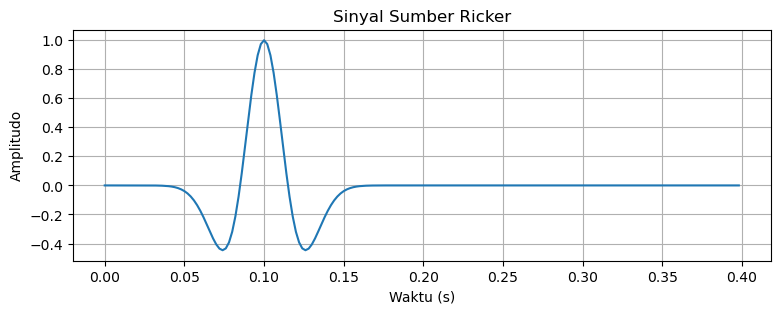

Simulasi selesai.
Ukuran wavefield: (200, 201)
Ukuran seismogram: (200, 3)


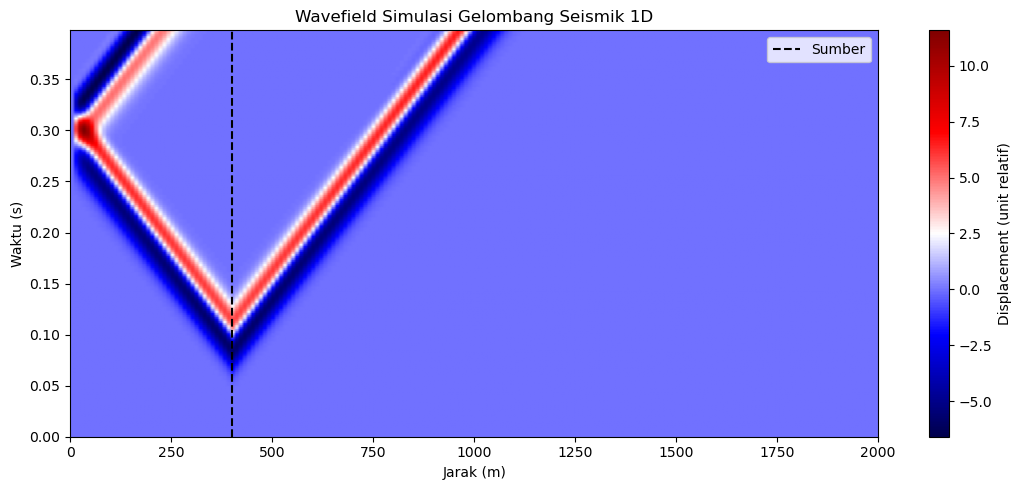

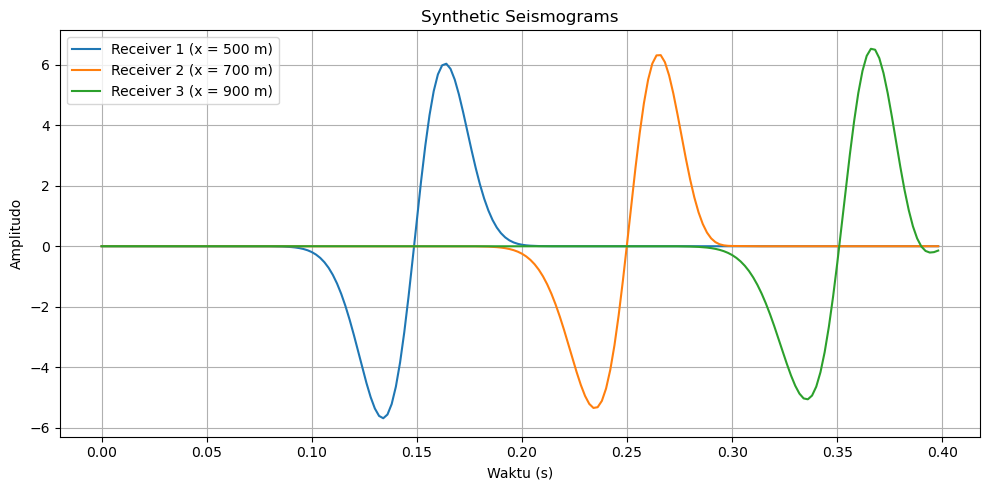

CFL <= 1: LULUS
Wavefield finite: LULUS
Seismograms finite: LULUS
Source response nonzero: LULUS
Grid sesuai: LULUS
Langkah waktu sesuai: LULUS


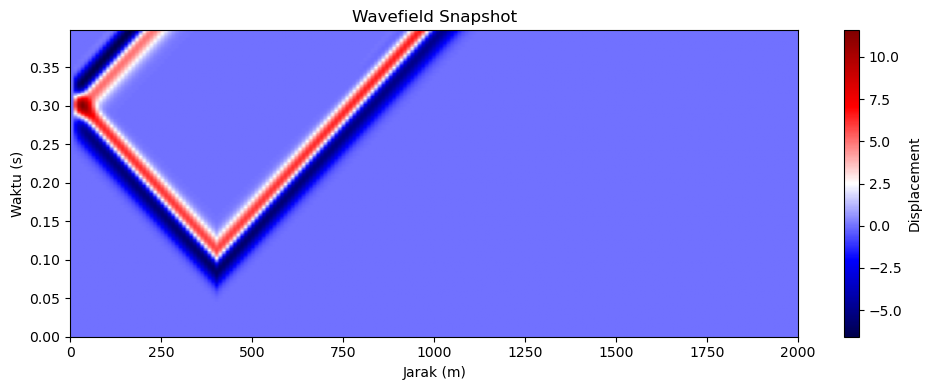

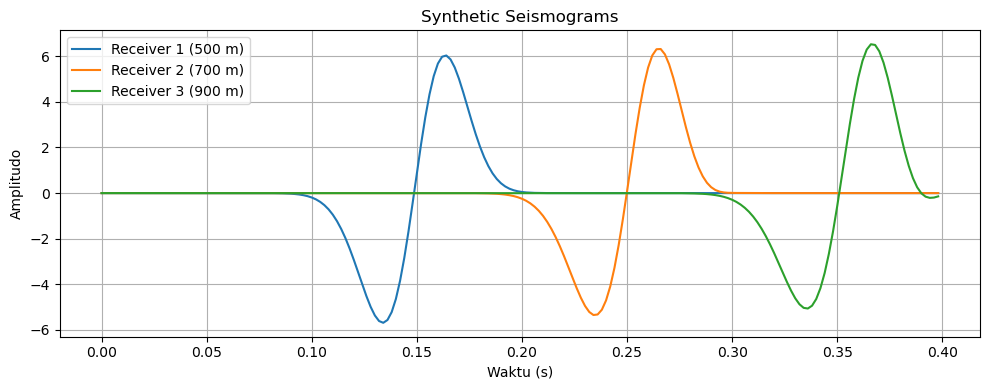

Hasil disimpan di: D:\Programss\PEMPROG\results_r_cs_004


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path

# Parameter utama sesuai deskripsi R-CS-004 dalam buku
NX = 201
NT = 200
CFL_TARGET = 0.4

# Parameter contoh untuk simulasi sintetis.
# Nilai ini bukan angka parameter asli yang dicantumkan dalam buku.
DX = 10.0              # Jarak antargrid (m)
VELOCITY = 2000.0      # Kecepatan gelombang konstan (m/s)
FREQUENCY = 15.0       # Frekuensi dominan sumber (Hz)

SOURCE_INDEX = 40
RECEIVER_INDICES = [50, 70, 90]

# Menghitung time step dari kondisi CFL
DT = CFL_TARGET * DX / VELOCITY
CFL = VELOCITY * DT / DX

x = np.arange(NX) * DX
time = np.arange(NT) * DT

print(f"Jumlah titik grid : {NX}")
print(f"Jumlah langkah waktu: {NT}")
print(f"DX                : {DX} m")
print(f"DT                : {DT:.6f} s")
print(f"CFL               : {CFL:.2f}")
print(f"Kecepatan         : {VELOCITY} m/s")

def ricker_wavelet(time, frequency, delay):
    """
    Membuat sumber gelombang Ricker.
    time   : array waktu (s)
    frequency : frekuensi dominan (Hz)
    delay  : waktu puncak sumber (s)
    """
    a = np.pi * frequency * (time - delay)
    return (1 - 2 * a**2) * np.exp(-a**2)


source_delay = 1.5 / FREQUENCY
source_signal = ricker_wavelet(time, FREQUENCY, source_delay)

plt.figure(figsize=(9, 3))
plt.plot(time, source_signal)
plt.title("Sinyal Sumber Ricker")
plt.xlabel("Waktu (s)")
plt.ylabel("Amplitudo")
plt.grid(True)
plt.show()

# Inisialisasi displacement pada dua waktu sebelumnya
u_previous = np.zeros(NX)
u_current = np.zeros(NX)

# Menyimpan wavefield setiap langkah waktu
wavefield = np.zeros((NT, NX))

# Menyimpan respons pada tiga receiver
seismograms = np.zeros((NT, len(RECEIVER_INDICES)))

# Koefisien finite difference
r = (VELOCITY * DT / DX) ** 2

for n in range(NT):
    u_next = np.zeros(NX)

    # Persamaan gelombang 1D dengan finite difference eksplisit
    u_next[1:-1] = (
        2 * u_current[1:-1]
        - u_previous[1:-1]
        + r * (
            u_current[2:]
            - 2 * u_current[1:-1]
            + u_current[:-2]
        )
    )

    # Menambahkan sumber pada titik sumber
    u_next[SOURCE_INDEX] += source_signal[n]

    # Fixed-end boundaries: kedua ujung bernilai nol
    u_next[0] = 0.0
    u_next[-1] = 0.0

    # Simpan wavefield dan data receiver
    wavefield[n, :] = u_next

    for j, receiver_index in enumerate(RECEIVER_INDICES):
        seismograms[n, j] = u_next[receiver_index]

    # Perbarui waktu
    u_previous = u_current.copy()
    u_current = u_next.copy()

print("Simulasi selesai.")
print("Ukuran wavefield:", wavefield.shape)
print("Ukuran seismogram:", seismograms.shape)

plt.figure(figsize=(11, 5))

plt.imshow(
    wavefield,
    aspect="auto",
    origin="lower",
    extent=[x[0], x[-1], time[0], time[-1]],
    cmap="seismic"
)

plt.colorbar(label="Displacement (unit relatif)")
plt.xlabel("Jarak (m)")
plt.ylabel("Waktu (s)")
plt.title("Wavefield Simulasi Gelombang Seismik 1D")
plt.axvline(x[SOURCE_INDEX], linestyle="--", color="black",
            label="Sumber")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

for j, receiver_index in enumerate(RECEIVER_INDICES):
    plt.plot(
        time,
        seismograms[:, j],
        label=f"Receiver {j + 1} (x = {x[receiver_index]:.0f} m)"
    )

plt.xlabel("Waktu (s)")
plt.ylabel("Amplitudo")
plt.title("Synthetic Seismograms")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

checks = {
    "CFL <= 1": CFL <= 1.0,
    "Wavefield finite": bool(np.isfinite(wavefield).all()),
    "Seismograms finite": bool(np.isfinite(seismograms).all()),
    "Source response nonzero": bool(np.any(np.abs(wavefield) > 0)),
    "Grid sesuai": NX == 201,
    "Langkah waktu sesuai": NT == 200
}

for name, passed in checks.items():
    print(f"{name}: {'LULUS' if passed else 'GAGAL'}")

assert all(checks.values()), "Ada pemeriksaan yang gagal."

output_dir = Path("results_r_cs_004")
output_dir.mkdir(exist_ok=True)

# Simpan wavefield dan seismogram
np.savetxt(
    output_dir / "wavefield.csv",
    wavefield,
    delimiter=","
)

np.savetxt(
    output_dir / "synthetic_seismograms.csv",
    seismograms,
    delimiter=","
)

# Simpan ringkasan parameter dan pemeriksaan
summary = {
    "recipe": "R-CS-004",
    "method": "Explicit finite-difference 1D wave equation",
    "grid_points": NX,
    "time_steps": NT,
    "dx_m": DX,
    "dt_s": DT,
    "velocity_m_per_s": VELOCITY,
    "cfl": CFL,
    "source_index": SOURCE_INDEX,
    "receiver_indices": RECEIVER_INDICES,
    "boundary_condition": "fixed-end",
    "checks": checks,
    "parameter_note": (
        "DX, velocity, frequency, source index, and receiver indices "
        "are illustrative values, not verified original book parameters."
    )
}

with open(output_dir / "summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)

# Simpan grafik wavefield
plt.figure(figsize=(10, 4))
plt.imshow(
    wavefield,
    aspect="auto",
    origin="lower",
    extent=[x[0], x[-1], time[0], time[-1]],
    cmap="seismic"
)
plt.colorbar(label="Displacement")
plt.xlabel("Jarak (m)")
plt.ylabel("Waktu (s)")
plt.title("Wavefield Snapshot")
plt.tight_layout()
plt.savefig(output_dir / "wavefield_snapshot.png", dpi=300)
plt.show()

# Simpan grafik seismogram
plt.figure(figsize=(10, 4))
for j, receiver_index in enumerate(RECEIVER_INDICES):
    plt.plot(time, seismograms[:, j],
             label=f"Receiver {j + 1} ({x[receiver_index]:.0f} m)")

plt.xlabel("Waktu (s)")
plt.ylabel("Amplitudo")
plt.title("Synthetic Seismograms")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(output_dir / "synthetic_seismograms.png", dpi=300)
plt.show()

print("Hasil disimpan di:", output_dir.resolve())

### **Kesimpulan**

Simulasi R-CS-004 menggunakan metode *explicit finite-difference* untuk memodelkan perambatan gelombang seismik sintetis pada medium satu dimensi, dengan 201 titik grid, 200 langkah waktu, dan CFL 0,4. Hasilnya berupa visualisasi *wavefield* dan tiga rekaman *synthetic seismogram* yang menunjukkan respons gelombang pada posisi penerima. Simulasi ini menjadi dasar pemeriksaan solver numerik, tetapi belum dapat digunakan untuk menggambarkan kondisi bawah permukaan sebenarnya karena tidak menggunakan data seismik lapangan.